## Problem 17
Write a Python program to perform basic morphological operations (Erosion, Dilation, Opening, Closing).

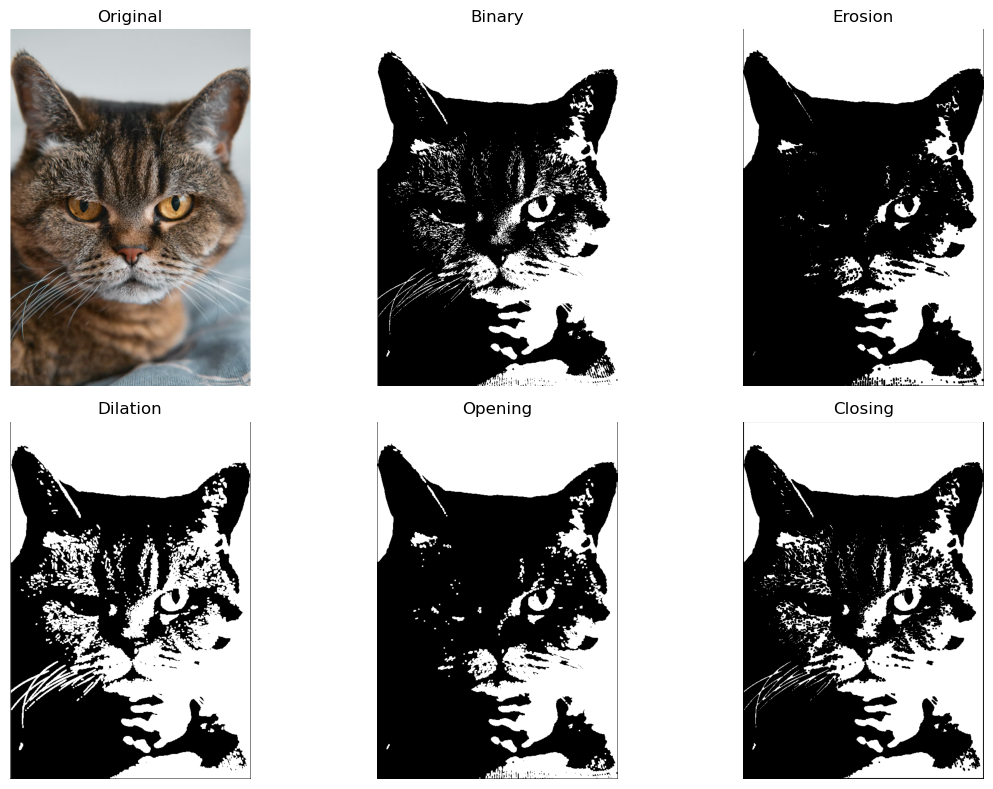

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

image = cv2.imread("cat.png")
height, width = image.shape[:2]
binary = np.zeros((height, width), dtype=np.uint8)

# Convert to binary manually.
for row in range(height):
    for col in range(width):
        blue = int(image[row, col, 0])
        green = int(image[row, col, 1])
        red = int(image[row, col, 2])
        gray = int(0.114 * blue + 0.587 * green + 0.299 * red)
        binary[row, col] = 255 if gray > 127 else 0

# A simple 3x3 square structuring element.
kernel = np.zeros((3, 3), dtype=np.uint8)
for row in range(3):
    for col in range(3):
        kernel[row, col] = 1

def erosion(source):
    result = np.zeros((height, width), dtype=np.uint8)
    for row in range(1, height - 1):
        for col in range(1, width - 1):
            keep = True
            for kr in range(3):
                for kc in range(3):
                    if kernel[kr, kc] == 1 and source[row + kr - 1, col + kc - 1] == 0:
                        keep = False
            if keep:
                result[row, col] = 255
    return result

def dilation(source):
    result = np.zeros((height, width), dtype=np.uint8)
    for row in range(1, height - 1):
        for col in range(1, width - 1):
            for kr in range(3):
                for kc in range(3):
                    if kernel[kr, kc] == 1 and source[row + kr - 1, col + kc - 1] == 255:
                        result[row, col] = 255
    return result

eroded = erosion(binary)
dilated = dilation(binary)
opened = dilation(eroded)
closed = erosion(dilated)

plt.figure(figsize=(12, 8))
plt.subplot(2, 3, 1)
plt.imshow(image[:, :, ::-1])
plt.title("Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(eroded, cmap="gray")
plt.title("Erosion")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(dilated, cmap="gray")
plt.title("Dilation")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(opened, cmap="gray")
plt.title("Opening")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(closed, cmap="gray")
plt.title("Closing")
plt.axis("off")
plt.tight_layout()
plt.show()
